# Exploración inicial — datos fuente

Primer vistazo al *dataset* NYC TLC yellow taxi, restringido al **primer
mes disponible (enero de 2023)**, leyendo el fichero parquet original
directamente desde la fuente. La intención es hacerse una idea rápida
del contenido — antes de cualquier limpieza o ingesta — sin pasar por
la capa bronze ni por Spark.

Este notebook precede narrativamente a `preprocess.ipynb`: las
observaciones que se abren aquí se desarrollan allí sobre el conjunto
completo (ya en bronze) y se traducen en las reglas de limpieza que
aplica silver.

Objetivos:

- conocer las columnas del *feed* TLC y sus tipos,
- evaluar la completitud: porcentaje de nulos por columna,
- cuantificar anomalías temporales: registros fuera del período y viajes con duración nula o negativa,
- identificar violaciones de consistencia lógica entre campos (importes negativos, distancia cero con tarifa, etc.),
- ver de un vistazo magnitudes y distribuciones a priori,
- detectar a alto nivel qué cosas requerirán limpieza más adelante.

In [1]:
import os
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd

In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo académico: fondo blanco, rejilla sutil, tipografía neutra y paleta
# muted ("deep" de seaborn). Sustituye al estilo expresivo "fivethirtyeight"
# del ejemplo de referencia, demasiado informal para un informe.
sns.set_theme(
    style="whitegrid",
    context="paper",
    palette="deep",
    rc={
        "figure.figsize": (9, 5),
        "figure.dpi": 110,
        "savefig.dpi": 150,
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.titleweight": "semibold",
        "axes.labelsize": 10,
        "axes.edgecolor": "#333333",
        "axes.linewidth": 0.8,
        "grid.color": "#dddddd",
        "grid.linewidth": 0.5,
        "xtick.labelsize": 9,
        "ytick.labelsize": 9,
        "lines.linewidth": 1.4,
        "patch.linewidth": 0.3,
        "legend.frameon": False,
        "legend.fontsize": 9,
    },
)
PALETTE = sns.color_palette("deep")

## 1. Subconjunto: enero de 2023

Trabajamos sobre el primer mes disponible (enero de 2023) y leemos
**directamente el fichero parquet original** publicado por NYC TLC, sin
pasar por la capa bronze. De este modo la exploración es independiente
del resto de la cadena (Spark, Nessie, Iceberg) y puede ejecutarse con
solo pandas. El fichero ronda los 100 MB y se descarga la primera vez
que se ejecuta el notebook.

La tabla de zonas (`taxi_zone_lookup.csv`, ~265 filas) se descarga
también de la fuente y se usa más abajo para etiquetar los conteos por
zona.

In [3]:
PARQUET_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet"
ZONES_URL   = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

# El bind mount /opt/spark/src queda persistente entre ejecuciones del
# contenedor — se reusa el fichero descargado.
TMP_DIR = Path("/opt/spark/src/.tmp_explore")
TMP_DIR.mkdir(parents=True, exist_ok=True)
PARQUET_PATH = TMP_DIR / "yellow_tripdata_2023-01.parquet"
ZONES_PATH   = TMP_DIR / "taxi_zone_lookup.csv"

if not PARQUET_PATH.exists():
    print(f"Descargando {PARQUET_URL}")
    urlretrieve(PARQUET_URL, PARQUET_PATH)
    print(f"  -> {PARQUET_PATH.stat().st_size / 1024 / 1024:.1f} MB")
if not ZONES_PATH.exists():
    print(f"Descargando {ZONES_URL}")
    urlretrieve(ZONES_URL, ZONES_PATH)
    print(f"  -> {ZONES_PATH.stat().st_size / 1024:.1f} KB")

yt_jan23 = pd.read_parquet(PARQUET_PATH)
zl       = pd.read_csv(ZONES_PATH)

n_yt = len(yt_jan23)
n_zl = len(zl)
print(f"Yellow taxi (2023-01):  {n_yt:>10,} filas, {len(yt_jan23.columns)} columnas")
print(f"Taxi zone lookup:       {n_zl:>10,} filas, {len(zl.columns)} columnas")

Descargando https://d37ci6vzurychx.cloudfront.net/trip-data/yellow_tripdata_2023-01.parquet
  -> 45.5 MB
Yellow taxi (2023-01):   3,066,766 filas, 19 columnas
Taxi zone lookup:              265 filas, 4 columnas


## 2. Esquema y muestra

Empezamos viendo qué columnas trae el *feed* y de qué tipo, junto a unas
pocas filas reales para hacernos una idea del contenido.

In [4]:
yt_jan23.dtypes

VendorID                          int64
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int64
DOLocationID                      int64
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
airport_fee                     float64
dtype: object

In [5]:
yt_jan23.head()

,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,airport_fee
0,2,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,1.0,N,161,141,2,9.3,1.00,0.5,0.00,0.0,1.0,14.30,2.5,0.00
1,2,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1.0,N,43,237,1,7.9,1.00,0.5,4.00,0.0,1.0,16.90,2.5,0.00
2,2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1.0,N,48,238,1,14.9,1.00,0.5,15.00,0.0,1.0,34.90,2.5,0.00
3,1,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1.0,N,138,7,1,12.1,7.25,0.5,0.00,0.0,1.0,20.85,0.0,1.25
4,2,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1.0,N,107,79,1,11.4,1.00,0.5,3.28,0.0,1.0,19.68,2.5,0.00


## 3. Calidad de los datos: completitud

Antes de mirar las distribuciones conviene saber si hay columnas con
huecos significativos. Calculamos el **porcentaje de valores `NULL` por
columna** sobre los millones de registros del mes — es la primera señal
de qué *features* podemos usar sin riesgos en pasos posteriores.

En el fichero de enero de 2023 la columna `cbd_congestion_fee` todavía
no existe (se añade en 2025); el resto de recargos —`airport_fee`
(introducido en 2022) y `congestion_surcharge` (en 2019)— ya aparecen,
al ser enero de 2023 posterior a su introducción. Algún recargo está
mayoritariamente a 0 — todo es esperable, no patológico.

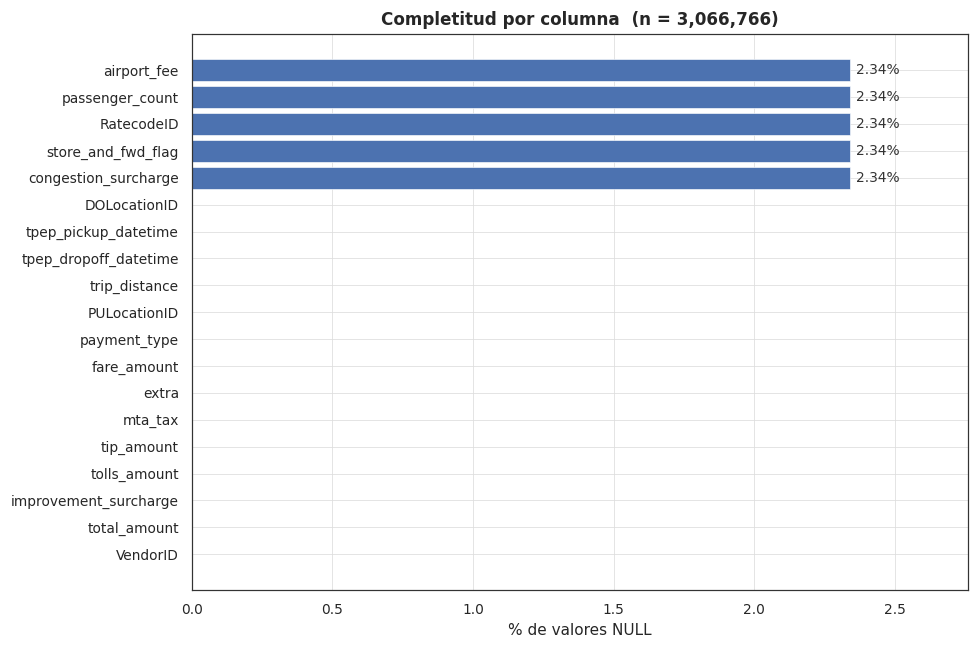

In [6]:
null_pct = (yt_jan23.isna().mean() * 100).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(null_pct.index, null_pct.values,
        color=PALETTE[0], edgecolor="white", linewidth=0.4)
ax.set_xlabel("% de valores NULL")
ax.set_title(f"Completitud por columna  (n = {n_yt:,})")

xmax = max(null_pct.max(), 0.5)
ax.set_xlim(0, xmax * 1.18)
for i, pct in enumerate(null_pct.values):
    if pct > 0.05:
        ax.text(pct + xmax * 0.01, i, f"{pct:.2f}%",
                va="center", fontsize=9, color="#333333")
plt.tight_layout()
plt.show()

## 4. Anomalías temporales

El *feed* de enero de 2023 debería contener únicamente viajes recogidos
dentro del mes. Sin embargo, suele incluir filas con `tpep_pickup_datetime`
de meses anteriores al de referencia (desfases de reloj o registros
tardíos). Aquí cuantificamos:

- registros cuyo `tpep_pickup_datetime` cae fuera del rango
  `[2023-01-01, 2023-02-01)`, desglosados por mes de origen;
- viajes con `tpep_dropoff_datetime ≤ tpep_pickup_datetime` (duración
  nula o negativa), que reflejan desfases de reloj o errores de registro.

Ambos grupos deben excluirse en la limpieza de silver.

In [7]:
JAN_START = pd.Timestamp("2023-01-01")
JAN_END   = pd.Timestamp("2023-02-01")

out_of_range = (
    (yt_jan23["tpep_pickup_datetime"] < JAN_START) |
    (yt_jan23["tpep_pickup_datetime"] >= JAN_END)
)
non_positive_dur = (
    yt_jan23["tpep_dropoff_datetime"] <= yt_jan23["tpep_pickup_datetime"]
)

n_oor = int(out_of_range.sum())
n_dur = int(non_positive_dur.sum())
n_tot = len(yt_jan23)

print(f"Registros con pickup fuera de enero 2023:  {n_oor:>8,}  ({n_oor / n_tot * 100:.2f}%)")
print(f"Viajes con duración ≤ 0:                   {n_dur:>8,}  ({n_dur / n_tot * 100:.2f}%)")
print(f"Total filas:                                {n_tot:>8,}")

if n_oor > 0:
    by_month = (
        yt_jan23.loc[out_of_range, "tpep_pickup_datetime"]
        .dt.to_period("M")
        .value_counts()
        .sort_index()
    )
    print(f"\nPickups fuera de rango desglosados por mes:")
    print(by_month.to_string())

Registros con pickup fuera de enero 2023:        48  (0.00%)
Viajes con duración ≤ 0:                      1,121  (0.04%)
Total filas:                                3,066,766

Pickups fuera de rango desglosados por mes:
tpep_pickup_datetime
2008-12     2
2022-10    11
2022-12    25
2023-02    10
Freq: M


## 5. Consistencia lógica entre campos

Más allá de los valores nulos, el dataset puede contener registros
internamente contradictorios: combinaciones de campos que son imposibles
o sospechosas aunque cada campo individualmente parezca válido.
Revisamos los cruces más relevantes para motivar las reglas de filtrado
de silver:

- **Distancia cero con tarifa positiva** o viceversa: el taxímetro no
  debería generar tarifa sin desplazamiento ni al contrario.
- **`passenger_count = 0`**: viaje sin pasajero registrado pero con
  pago; puede ser un error de registro o un viaje de prueba.
- **Importes negativos** en `fare_amount`, `total_amount` o `tip_amount`:
  reflejan correcciones o cancelaciones mal gestionadas; deben excluirse
  del análisis de ingresos.

Violaciones de consistencia lógica (n total = 3,066,766):

                                           n  % del total
violación                                                
passenger_count = 0                    51164        1.668
trip_distance = 0  y  fare_amount > 0  42225        1.377
total_amount < 0                       25204        0.822
fare_amount < 0                        25049        0.817
trip_distance > 0  y  fare_amount = 0    485        0.016
tip_amount < 0                           225        0.007
trip_distance < 0                          0        0.000


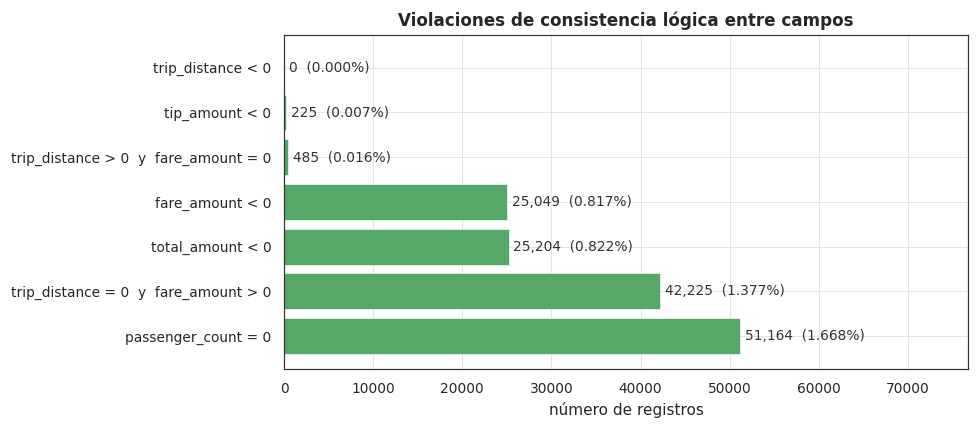

In [8]:
checks = {
    "trip_distance = 0  y  fare_amount > 0":
        (yt_jan23["trip_distance"] == 0) & (yt_jan23["fare_amount"] > 0),
    "trip_distance > 0  y  fare_amount = 0":
        (yt_jan23["trip_distance"] > 0) & (yt_jan23["fare_amount"] == 0),
    "passenger_count = 0":
        yt_jan23["passenger_count"] == 0,
    "fare_amount < 0":
        yt_jan23["fare_amount"] < 0,
    "total_amount < 0":
        yt_jan23["total_amount"] < 0,
    "tip_amount < 0":
        yt_jan23["tip_amount"] < 0,
    "trip_distance < 0":
        yt_jan23["trip_distance"] < 0,
}

n_total = len(yt_jan23)
rows = [
    {"violación": desc, "n": int(mask.sum()), "% del total": mask.sum() / n_total * 100}
    for desc, mask in checks.items()
]
df_checks = (
    pd.DataFrame(rows)
    .set_index("violación")
    .sort_values("n", ascending=False)
)
print(f"Violaciones de consistencia lógica (n total = {n_total:,}):\n")
print(df_checks.to_string(float_format=lambda x: f"{x:.3f}"))

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(df_checks.index, df_checks["n"],
        color=PALETTE[2], edgecolor="white", linewidth=0.4)
ax.set_xlabel("número de registros")
ax.set_title("Violaciones de consistencia lógica entre campos")
xmax = df_checks["n"].max()
for i, (n, pct) in enumerate(zip(df_checks["n"], df_checks["% del total"])):
    ax.text(n + xmax * 0.01, i, f"{n:,}  ({pct:.3f}%)",
            va="center", fontsize=9, color="#333333")
ax.set_xlim(0, xmax * 1.5)
plt.tight_layout()
plt.show()

## 6. Distribución a priori de las variables numéricas

Resumen estadístico (recuento, media, desviación típica, mínimo, máximo
y percentiles representativos) de las principales variables continuas,
calculado sobre el **dataset completo**. Permite intuir la forma de cada
distribución: ¿simétrica?, ¿asimétrica con cola larga?, ¿hay valores
negativos imposibles? Las distancias entre p99 y `max` o entre `min` y
p1 anticipan dónde habrá que poner topes en silver.

In [9]:
numeric_cols = [
    "trip_distance", "passenger_count", "fare_amount", "extra", "mta_tax",
    "tip_amount", "tolls_amount", "improvement_surcharge", "total_amount",
    "congestion_surcharge",
]
yt_jan23[numeric_cols].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
).round(3)

,trip_distance,passenger_count,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge
count,3066766.000,2995023.000,3066766.000,3066766.000,3066766.000,3066766.000,3066766.000,3066766.000,3066766.000,2995023.000
mean,3.847,1.363,18.367,1.538,0.488,3.368,0.518,0.982,27.020,2.274
std,249.584,0.896,17.808,1.790,0.103,3.827,2.018,0.183,22.164,0.772
min,0.000,0.000,-900.000,-7.500,-0.500,-96.220,-65.000,-1.000,-751.000,-2.500
1%,0.000,0.000,3.000,0.000,0.000,0.000,0.000,0.300,5.500,0.000
25%,1.060,1.000,8.600,0.000,0.500,1.000,0.000,1.000,15.400,2.500
50%,1.800,1.000,12.800,1.000,0.500,2.720,0.000,1.000,20.160,2.500
75%,3.330,1.000,20.500,2.500,0.500,4.200,0.000,1.000,28.700,2.500
95%,14.320,3.000,65.300,5.000,0.500,11.110,6.550,1.000,80.250,2.500
99%,20.060,5.000,72.300,7.500,0.500,17.110,6.550,1.000,101.940,2.500


A continuación los histogramas dan la forma visual.
**Recortamos a `[p1, p99]`** antes de pintar: el 1 % de outliers extremos
(p. ej. `fare_amount` con máximos desorbitados, o duraciones negativas por
desfases de reloj) colapsaría el histograma a una sola barra. La caja
entre p1 y p99 contiene el 98 % de las observaciones — basta para
apreciar asimetría, modas y colas.

Tanto los histogramas como el resto del análisis bivariado se calculan
sobre **todo el dataset** (varios millones de filas), no sobre una muestra:
trabajamos con el `DataFrame` completo en pandas, sin submuestreo.

In [10]:
# Duración del viaje (minutos), calculada sobre el dataset completo.
# La reusaremos en histogramas, correlaciones y hexbin.
yt_jan23["trip_duration_min"] = (
    (yt_jan23["tpep_dropoff_datetime"] - yt_jan23["tpep_pickup_datetime"])
    .dt.total_seconds() / 60.0
)
print(f"Filas para los análisis (dataset completo): {len(yt_jan23):,}")

Filas para los análisis (dataset completo): 3,066,766


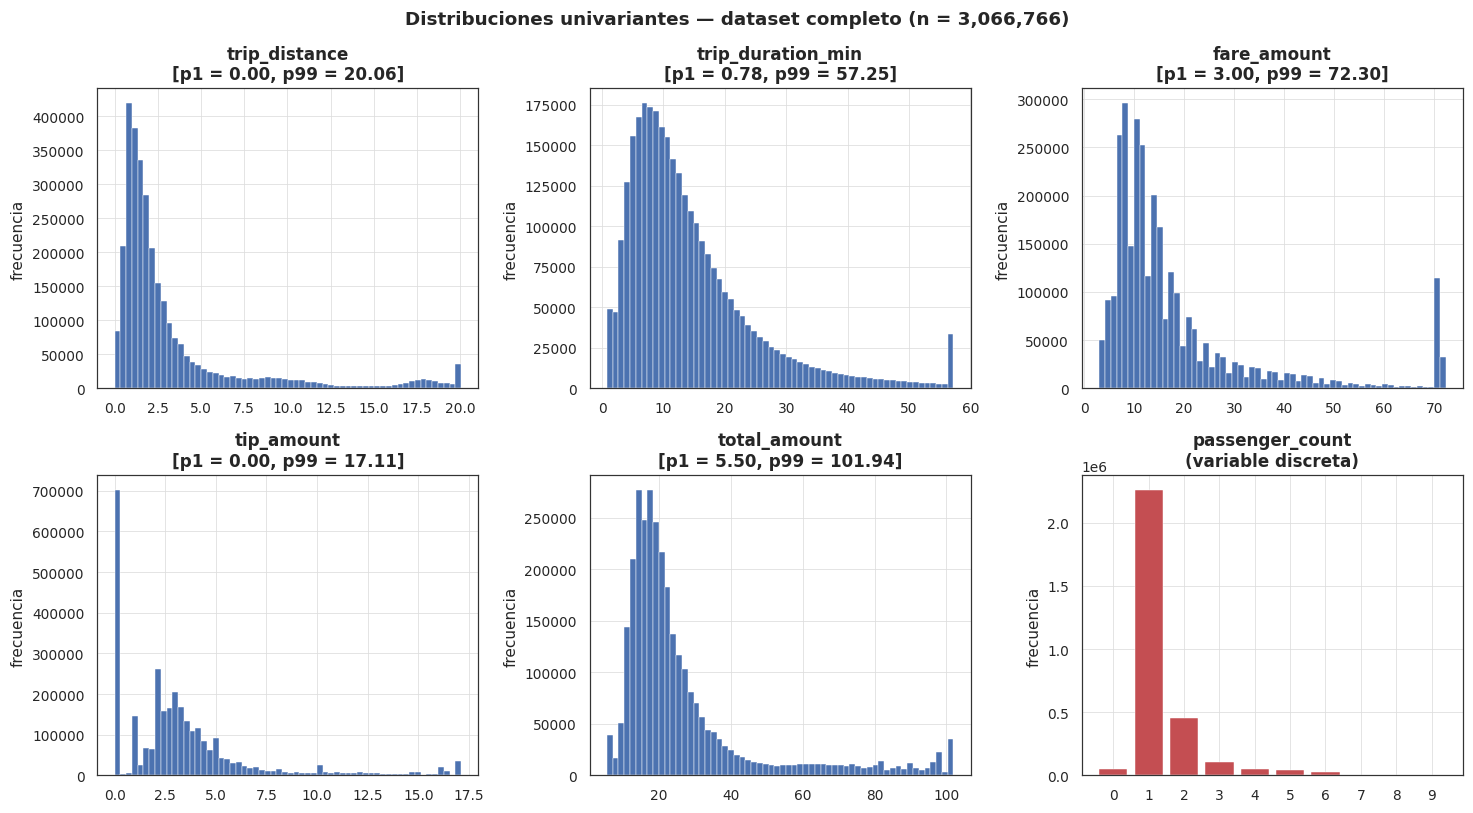

In [11]:
hist_cols = [
    "trip_distance", "trip_duration_min", "fare_amount",
    "tip_amount", "total_amount",
]
fig, axes = plt.subplots(2, 3, figsize=(13.5, 7.5))
for ax, c in zip(axes.flat[:5], hist_cols):
    p1, p99 = yt_jan23[c].quantile([0.01, 0.99])
    ax.hist(yt_jan23[c].clip(p1, p99), bins=60,
            color=PALETTE[0], edgecolor="white", linewidth=0.3)
    ax.set_title(f"{c}\n[p1 = {p1:.2f}, p99 = {p99:.2f}]")
    ax.set_ylabel("frecuencia")

# passenger_count es discreto: bar plot por valor.
pc = yt_jan23["passenger_count"].dropna().astype(int).value_counts().sort_index()
ax = axes.flat[5]
ax.bar(pc.index.astype(str), pc.values,
       color=PALETTE[3], edgecolor="white", linewidth=0.3)
ax.set_title("passenger_count\n(variable discreta)")
ax.set_ylabel("frecuencia")

fig.suptitle(f"Distribuciones univariantes — dataset completo (n = {len(yt_jan23):,})",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
plt.show()

## 7. Variables categóricas

Conteos por valor para los códigos que el *feed* utiliza: `VendorID`
(empresa que opera el taxímetro), `RatecodeID` (tipo de tarifa),
`payment_type` (forma de pago) y `store_and_fwd_flag` (registro local
diferido). Sirve para detectar valores que aparecen pero no figuran en el
diccionario TLC.

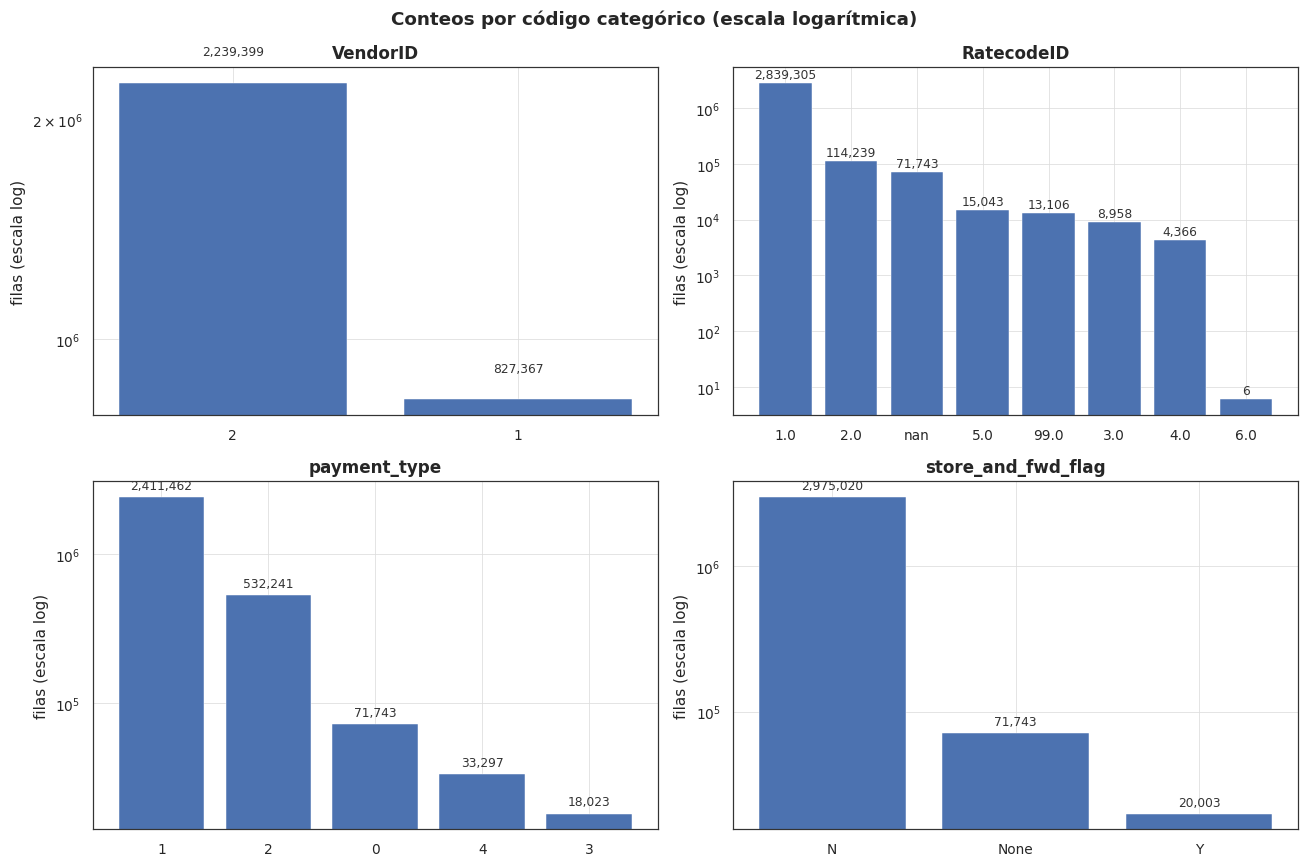

In [12]:
# Bar chart por código categórico — escala log en y para que los valores
# minoritarios (RatecodeID=99, payment_type=0/4, NULLs) sean visibles junto
# a los dominantes. Anotamos el conteo exacto sobre cada barra.
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
specs = [
    ("VendorID", axes[0, 0]),
    ("RatecodeID", axes[0, 1]),
    ("payment_type", axes[1, 0]),
    ("store_and_fwd_flag", axes[1, 1]),
]
for col_name, ax in specs:
    counts = yt_jan23[col_name].astype(str).value_counts()
    bars = ax.bar(counts.index, counts.values,
                  color=PALETTE[0], edgecolor="white", linewidth=0.3)
    ax.set_yscale("log")
    ax.set_title(col_name)
    ax.set_ylabel("filas (escala log)")
    for bar, value in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width() / 2,
                bar.get_height() * 1.08,
                f"{value:,}", ha="center", va="bottom",
                fontsize=8, color="#333333")

fig.suptitle("Conteos por código categórico (escala logarítmica)",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
plt.show()

## 8. Patrón temporal

¿Cómo se distribuyen las recogidas a lo largo del mes y a lo largo del
día? Es la vista más básica para confirmar que la cobertura del mes es
completa y que aparece el patrón típico horario (valles de madrugada,
picos de mañana y tarde).

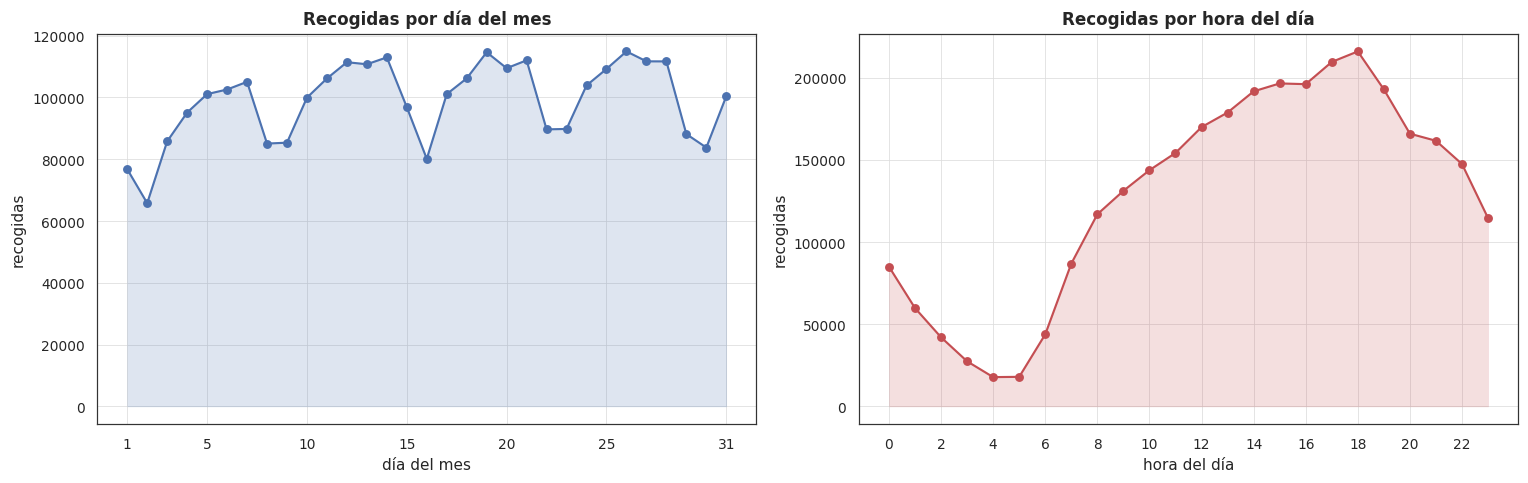

In [13]:
day_df = yt_jan23["tpep_pickup_datetime"].dt.day.value_counts().sort_index()
hour_df = yt_jan23["tpep_pickup_datetime"].dt.hour.value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(day_df.index, day_df.values, marker="o", color=PALETTE[0])
axes[0].fill_between(day_df.index, day_df.values, alpha=0.18, color=PALETTE[0])
axes[0].set_title("Recogidas por día del mes")
axes[0].set_xlabel("día del mes")
axes[0].set_ylabel("recogidas")
axes[0].set_xticks([1, 5, 10, 15, 20, 25, 31])

axes[1].plot(hour_df.index, hour_df.values, marker="o", color=PALETTE[3])
axes[1].fill_between(hour_df.index, hour_df.values, alpha=0.18, color=PALETTE[3])
axes[1].set_title("Recogidas por hora del día")
axes[1].set_xlabel("hora del día")
axes[1].set_ylabel("recogidas")
axes[1].set_xticks(range(0, 24, 2))

fig.tight_layout()
plt.show()

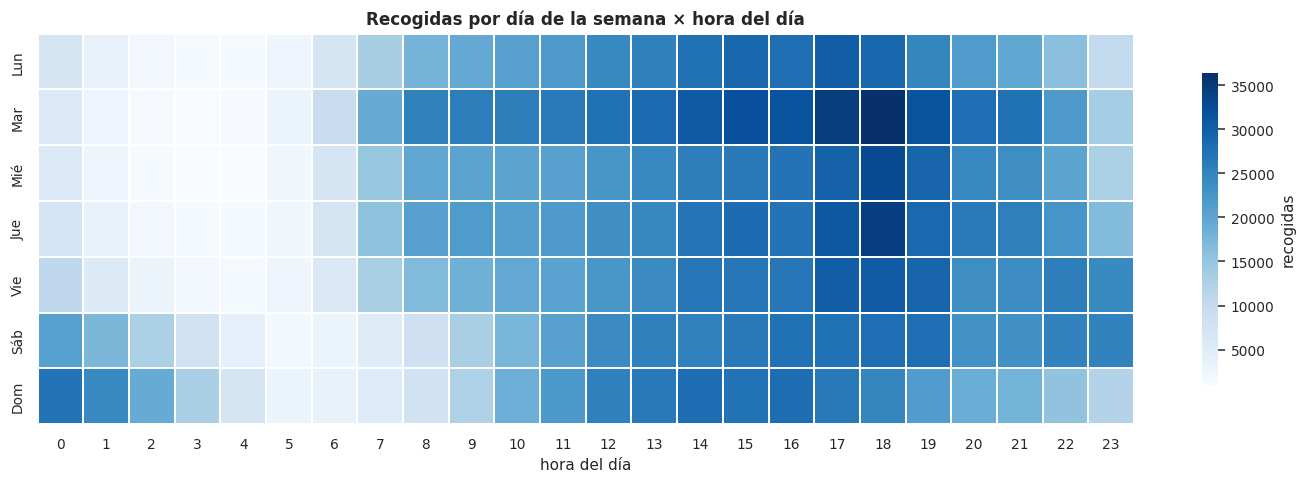

In [14]:
# pandas dt.dayofweek: 0=Lunes ... 6=Domingo
heat = (
    pd.DataFrame({
        "dow":  yt_jan23["tpep_pickup_datetime"].dt.dayofweek,
        "hour": yt_jan23["tpep_pickup_datetime"].dt.hour,
    })
    .value_counts().reset_index(name="count")
)
labels = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
heat["dow_label"] = heat["dow"].map(lambda i: labels[i])
pivot = (
    heat.pivot(index="dow_label", columns="hour", values="count")
    .reindex(labels)
)

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.heatmap(
    pivot, cmap="Blues", linewidths=0.3, linecolor="white",
    cbar_kws={"label": "recogidas", "shrink": 0.8}, ax=ax,
)
ax.set_title("Recogidas por día de la semana × hora del día")
ax.set_xlabel("hora del día")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

## 9. Zonas con más actividad

Cruzamos los conteos por `PULocationID` y `DOLocationID` con la tabla
`taxi_zone_lookup` para tener nombres legibles. El *top* da una idea
rápida de la geografía dominante de los viajes — esperaríamos Manhattan
y los aeropuertos (JFK, LGA, EWR) entre los primeros.

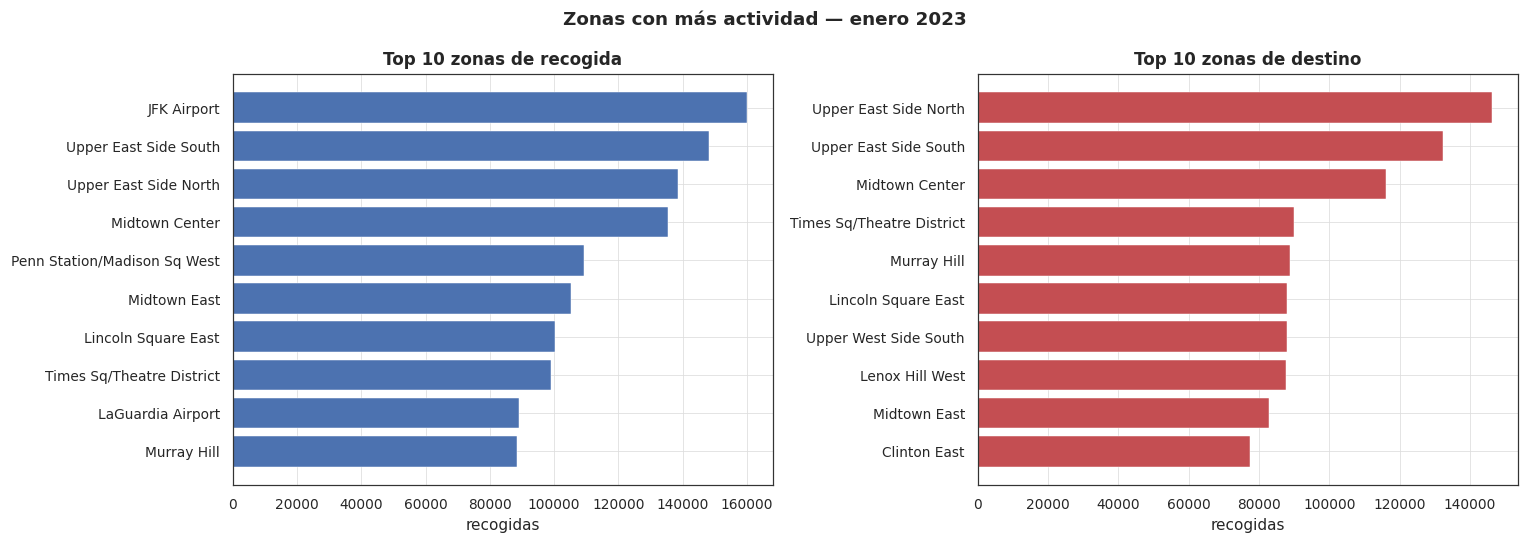

In [15]:
# Cruzamos los conteos por PU/DO con la tabla de zonas para tener nombres
# legibles. Barras horizontales — los nombres son largos y el ranking se
# aprecia de un vistazo.
zone_lookup = zl.set_index("LocationID")[["Borough", "Zone"]]

top_pu = (
    yt_jan23["PULocationID"].value_counts().head(10)
    .rename_axis("LocationID").reset_index(name="count")
    .merge(zone_lookup, on="LocationID", how="left")
    .sort_values("count")
)
top_do = (
    yt_jan23["DOLocationID"].value_counts().head(10)
    .rename_axis("LocationID").reset_index(name="count")
    .merge(zone_lookup, on="LocationID", how="left")
    .sort_values("count")
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(top_pu["Zone"], top_pu["count"],
             color=PALETTE[0], edgecolor="white", linewidth=0.3)
axes[0].set_title("Top 10 zonas de recogida")
axes[0].set_xlabel("recogidas")

axes[1].barh(top_do["Zone"], top_do["count"],
             color=PALETTE[3], edgecolor="white", linewidth=0.3)
axes[1].set_title("Top 10 zonas de destino")
axes[1].set_xlabel("recogidas")

fig.suptitle("Zonas con más actividad — enero 2023",
             fontsize=12, fontweight="semibold")
fig.tight_layout()
plt.show()

## 10. Relaciones entre variables

Una vez vistas las variables por separado, miramos cómo se relacionan
entre sí. Combinamos dos vistas:

- una **matriz de correlaciones** (Pearson) sobre las variables continuas,
  para detectar redundancias evidentes (`total_amount` ≈ suma de sus
  componentes), señales fuertes hacia variables de salida (`tip_amount`,
  `trip_duration_min`) y *features* casi constantes (poco poder
  discriminante);
- un **hexbin** del par con la correlación más alta —
  `fare_amount × trip_distance` — para ver la forma real de la relación
  más allá del coeficiente lineal: la banda principal corresponde a la
  tarifa por milla del taxímetro, y las bandas horizontales superiores
  delatan tarifas planas (p. ej. JFK ↔ Manhattan, ~70 USD).

Ambas vistas se calculan sobre **todo el dataset** (varios millones de
filas). Cualquier columna íntegramente nula en el mes se excluye
automáticamente para que no aparezcan filas vacías en la matriz.

Dos consideraciones técnicas sobre el cálculo:

- **Columnas casi constantes** (`mta_tax`, `improvement_surcharge`,
  `congestion_surcharge` en enero de 2023): su percentil p1 coincide con
  p99, por lo que el recorte se omite para esas columnas — aplicarlo las
  convertiría en constantes puras e invalidaría la correlación de Pearson.
- **Cero negativo IEEE 754**: correlaciones muy próximas a cero pueden
  dar `-0.0` tras redondear a 2 decimales, mostrándose como `-0.00`.
  Se normalizan a `0.0` antes de renderizar el heatmap.

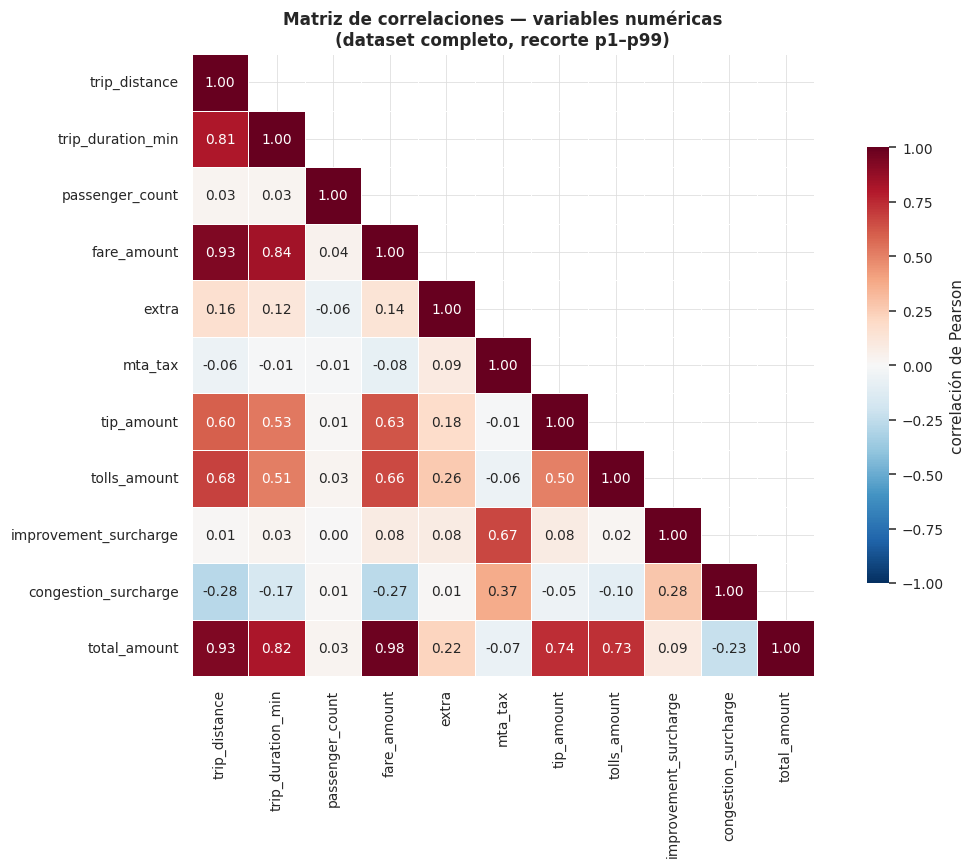

In [16]:
corr_cols = [
    "trip_distance", "trip_duration_min", "passenger_count",
    "fare_amount", "extra", "mta_tax", "tip_amount", "tolls_amount",
    "improvement_surcharge", "congestion_surcharge", "total_amount",
]
# Filtramos columnas íntegramente nulas o ausentes en este mes — producen
# filas vacías (toda NaN) que distorsionan la lectura de la matriz.
present_cols = [
    c for c in corr_cols
    if c in yt_jan23.columns and yt_jan23[c].notna().any()
]
dropped = [c for c in corr_cols if c not in present_cols]
if dropped:
    print(f"Columnas excluidas (vacías o ausentes): {dropped}")

# Recortamos a [p1, p99] antes de correlacionar: los outliers extremos
# (fares de 6 cifras, duraciones negativas por desfases de reloj) distorsionan
# Pearson y harían parecer débiles relaciones que en realidad son fuertes.
# Excepción: columnas donde p1 == p99 (casi constantes, p. ej. mta_tax,
# improvement_surcharge, congestion_surcharge en 2023-01) — aplicar el clip
# las convertiría en constantes puras e invalidaría Pearson. En esos casos
# se conservan los valores originales.
clip_lo = yt_jan23[present_cols].quantile(0.01)
clip_hi = yt_jan23[present_cols].quantile(0.99)
clipped = yt_jan23[present_cols].copy()
for c in present_cols:
    if clip_lo[c] < clip_hi[c]:
        clipped[c] = clipped[c].clip(clip_lo[c], clip_hi[c])

corr = clipped.corr()

# Preparamos la matriz de anotaciones: redondeamos a 2 decimales y
# convertimos el cero negativo IEEE 754 (-0.0) a cero positivo para evitar
# que fmt=".2f" lo muestre como "-0.00".
corr_display = corr.round(2)
corr_display[corr_display == 0] = 0

# Mostramos solo el triángulo inferior — la matriz es simétrica.
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    corr_display, mask=mask, annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True,
    linewidths=0.4, linecolor="white",
    annot_kws={"size": 9},
    cbar_kws={"label": "correlación de Pearson", "shrink": 0.7},
    ax=ax,
)
ax.set_title("Matriz de correlaciones — variables numéricas\n(dataset completo, recorte p1–p99)")
plt.tight_layout()
plt.show()

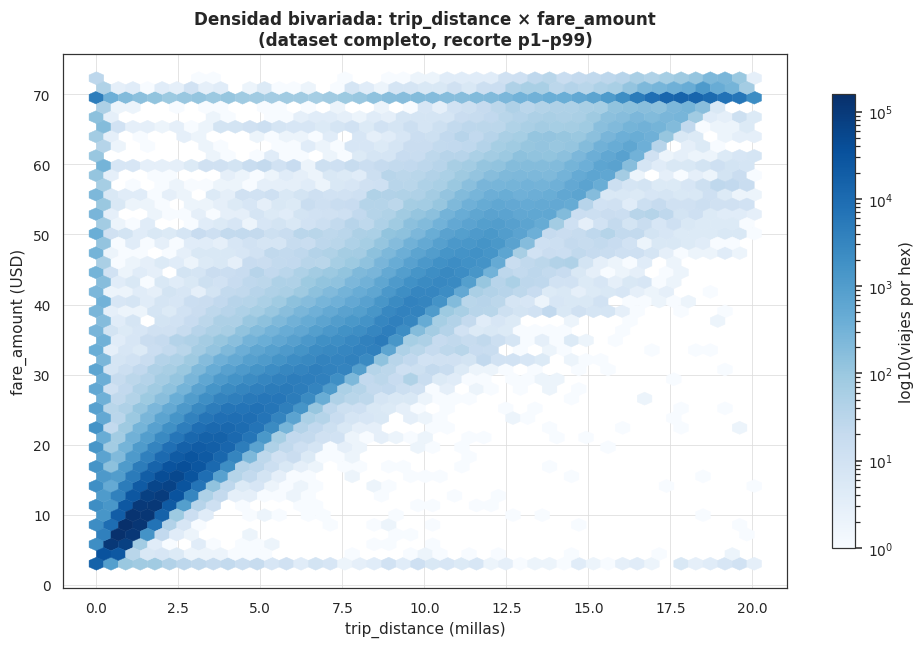

In [17]:
# Hexbin del par más fuerte: fare_amount × trip_distance, sobre el dataset
# completo. Hexbin agrega densidad y escala bien con millones de puntos.
clip_d = yt_jan23["trip_distance"].quantile([0.01, 0.99])
clip_f = yt_jan23["fare_amount"].quantile([0.01, 0.99])
mask = (
    yt_jan23["trip_distance"].between(clip_d.iloc[0], clip_d.iloc[1])
    & yt_jan23["fare_amount"].between(clip_f.iloc[0], clip_f.iloc[1])
)
sub = yt_jan23.loc[mask, ["trip_distance", "fare_amount"]]

fig, ax = plt.subplots(figsize=(9, 6))
hb = ax.hexbin(
    sub["trip_distance"], sub["fare_amount"],
    gridsize=45, cmap="Blues", mincnt=1, bins="log",
)
fig.colorbar(hb, ax=ax, label="log10(viajes por hex)", shrink=0.85)
ax.set_title("Densidad bivariada: trip_distance × fare_amount\n(dataset completo, recorte p1–p99)")
ax.set_xlabel("trip_distance (millas)")
ax.set_ylabel("fare_amount (USD)")
plt.tight_layout()
plt.show()

## 11. Observaciones de esta primera mirada

Lo que esta exploración sugiere y que se profundiza en `preprocess.ipynb`
con el conjunto completo:

- **Completitud**: la mayoría de columnas están casi siempre informadas.
  En el fichero de enero de 2023, `cbd_congestion_fee` todavía no existe
  como columna (se añade en 2025); el resto de recargos ya aparecen, al
  ser un mes posterior a su introducción — esperable y no patológico.
- **Anomalías temporales**: el *feed* de enero de 2023 contiene registros
  con `tpep_pickup_datetime` de meses anteriores al de referencia y viajes
  con duración nula o negativa por desfases de reloj. Ambos grupos deben
  excluirse en silver.
- **Magnitudes sospechosas** en importes y distancia: mínimos negativos y
  máximos varios órdenes de magnitud por encima del p99 en `fare_amount`
  o `total_amount`. Conviene investigar tanto la cola inferior como la
  superior.
- **Violaciones lógicas entre campos**: combinaciones imposibles —
  distancia cero con tarifa positiva, importes negativos, viajes sin
  pasajero — que el cruce de columnas de la sección 5 cuantifica y que
  las reglas de filtrado de silver deben cubrir explícitamente.
- **Códigos categóricos**: junto a los valores dominantes la escala log
  saca a la luz códigos minoritarios (`RatecodeID=99` «desconocido»,
  `payment_type=0`); hay que contrastarlos formalmente con el diccionario
  TLC. `preprocess.ipynb` lo hace sobre el histórico completo y confirma
  que todos los códigos presentes figuran en él — las pérdidas categóricas
  en silver provienen de `NULL` estructurales, no de códigos inválidos.
- **Esquema**: el *feed* mezcla tipos numéricos heterogéneos entre años;
  bronze los normaliza tras un *schema drift* histórico.
- **Volumen**: un solo mes ya ronda los millones de filas — pandas lo
  maneja en memoria, pero sobre el histórico completo se justifica el
  paso a Spark/Iceberg.
- **Patrón temporal**: días laborables presentan dos picos (mañana y
  tarde-noche), mientras que los fines de semana tienen el pico desplazado
  a la madrugada — útil para *features* horario/día como entrada de modelo.
- **Relaciones**: la matriz de correlaciones confirma la redundancia de
  `total_amount` con sus componentes y el vínculo fuerte
  `trip_distance ↔ fare_amount ↔ trip_duration_min`. Variables casi
  constantes (`mta_tax`, `improvement_surcharge`) aportan poca señal.
  El *hexbin* `fare_amount × trip_distance` muestra la banda lineal
  dominante (tarifa por milla del taxímetro) y bandas horizontales que
  delatan **tarifas planas** — la más visible corresponde a la tarifa
  fija JFK ↔ Manhattan.

A partir de aquí, `preprocess.ipynb` recorre los Q1 completos (2023, 2024
y 2025) y formaliza, con evidencia cuantitativa, las reglas de limpieza
que aplica `src/pipelines/silver/clean_yellow_taxi.py`.